<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/observabilite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



```
## Ce texte est au format code
```

# Observabilité d'un objet — astropy

Trois graphes depuis un site donné :
1. **Cette nuit** : hauteur de l'objet et de la Lune, crépuscules, masse d'air, azimuts.
2. **Vue du ciel** (type airmass.org) : zénith au centre, horizon au bord, N en haut, E à gauche.
3. **Sur un an** : heures exploitables par nuit (objet au-dessus du seuil en nuit astronomique), avec la part gênée par la Lune.
4. **Quand observer dans la nuit** : carte date × heure TU montrant les créneaux utiles, avec ou sans Lune.

Précision moyenne : pas de 5 min pour la nuit, 1 jour × 10 min pour l'année. Toutes les heures sont en **temps universel (TU)**.

In [1]:
!pip -q install astropy

## Paramètres à saisir

Remplir le formulaire à droite (Colab), puis *Exécution → Tout exécuter*.

- **Observatoire** : latitude et longitude en **degrés et minutes** (minutes décimales acceptées, secondes optionnelles), avec N/S et E/O ou un signe (Nord et Est positifs). Ex. : `43°36.7' N`, `43 36.7`, `1°20.1' E`, `-70 44.4`, `30°14'24" S`. Altitude en mètres.
- **Objet** : RA et Dec J2000, aux formats `21h11m48s` / `21:11:48` / `21 11 48` pour la RA (en heures), `+59d59m12s` / `+59:59:12` / `+59 59 12` pour la Dec (en degrés).
- **Nuit** : date du soir où commence la nuit (AAAA-MM-JJ).

In [2]:
# --- Observatoire ---
SITE_NAME = "Lias"  #@param {type:"string"}
LAT = "43.55929887406761"       #@param {type:"string"} , 1.1148670783279557
LON = "1.1148670783279557"        #@param {type:"string"}
HEIGHT = 200             #@param {type:"number"}

# --- Objet (J2000) ---
OBJ_NAME = "Ou4"         #@param {type:"string"}
RA = "21h11m48s"         #@param {type:"string"}
DEC = "+59d59m12s"       #@param {type:"string"}

# --- Nuit (soir de début) ---
NIGHT = "2026-11-06"     #@param {type:"date"}

# --- Critères ---
ALT_MIN = 30             #@param {type:"number"}
ILLUM_GENE = 0.50        #@param {type:"slider", min:0, max:1, step:0.05}
ILLUM_BANDE = 0.75       #@param {type:"slider", min:0, max:1, step:0.05}
STEP_NIGHT = 5           #@param {type:"integer"}
STEP_YEAR = 10           #@param {type:"integer"}

OUTFILE = "observabilite.png"

## Imports et configuration

In [3]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm
from datetime import datetime, date, timedelta, timezone

import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, GCRS, get_sun, get_body
from astropy.utils import iers

iers.conf.auto_max_age = None   # tolère des tables IERS un peu anciennes (précision moyenne)
warnings.filterwarnings("ignore")

import re
def dm_to_deg(s, neg="SWO"):
    # ex. 43°36.7' N | 43 36.7 | -1 20.1 | 30°14'24" S  ->  degrés décimaux
    s = str(s).strip().upper()
    sign = -1 if (s.startswith("-") or any(c in neg for c in re.sub(r"[^A-Z]", "", s))) else 1
    nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s.replace(",", "."))]
    if not nums or len(nums) > 3:
        raise ValueError(f"Coordonnée illisible : {s!r}")
    deg = nums[0] + (nums[1] / 60 if len(nums) > 1 else 0) + (nums[2] / 3600 if len(nums) > 2 else 0)
    return sign * deg

def deg_to_dm(x, pos, neg):
    h = pos if x >= 0 else neg
    x = abs(x); d = int(x); m = (x - d) * 60
    return f"{d}°{m:04.1f}' {h}"

LAT_DEG, LON_DEG = dm_to_deg(LAT, neg="S"), dm_to_deg(LON, neg="WO")
UTC = timezone.utc
site = EarthLocation(lat=LAT_DEG * u.deg, lon=LON_DEG * u.deg, height=float(HEIGHT) * u.m)
target = SkyCoord(RA, DEC, unit=(u.hourangle, u.deg), frame="icrs")
print(f"Site : {SITE_NAME}  {deg_to_dm(LAT_DEG, 'N', 'S')}  {deg_to_dm(LON_DEG, 'E', 'O')}"
      f"  ({LAT_DEG:+.4f}°, {LON_DEG:+.4f}°)  alt {HEIGHT:.0f} m")
print(f"Objet : {OBJ_NAME}  RA {target.ra.to_string(u.hour, sep='hms', precision=0)}"
      f"  Dec {target.dec.to_string(sep='dms', precision=0, alwayssign=True)}")
# minuit solaire moyen en TU pour ce site (centre de la nuit)
SOLAR_MIDNIGHT_OFFSET = timedelta(hours=-LON_DEG / 15)
MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août",
        "sept.", "oct.", "nov.", "déc."]

Site : Lias  43°33.6' N  1°06.9' E  (+43.5593°, +1.1149°)  alt 200 m
Objet : Ou4  RA 21h11m48s  Dec +59d59m12s


## Calcul — la nuit (TU)

In [4]:
d0 = date.fromisoformat(str(NIGHT))
d1 = d0 + timedelta(days=1)
mid = datetime(d1.year, d1.month, d1.day, tzinfo=UTC) + SOLAR_MIDNIGHT_OFFSET
t0_ut = (mid - timedelta(hours=8.5)).replace(minute=0, second=0, microsecond=0)
t1_ut = t0_ut + timedelta(hours=17)                           # fenêtre de 17 h autour de minuit solaire
n = int((t1_ut - t0_ut).total_seconds() / (STEP_NIGHT * 60)) + 1
times = Time(t0_ut) + np.linspace(0, (t1_ut - t0_ut).total_seconds(), n) * u.s
frame = AltAz(obstime=times, location=site)

aa_t = target.transform_to(frame)
alt_t, az_t = aa_t.alt.deg, aa_t.az.deg
sun_alt = get_sun(times).transform_to(frame).alt.deg
moon_aa = get_body("moon", times, site).transform_to(frame)
moon_alt, moon_az = moon_aa.alt.deg, moon_aa.az.deg

tm = times[n // 2]
sun_c, moon_c = get_sun(tm), get_body("moon", tm, site)
illum = (1 - np.cos(sun_c.separation(moon_c).rad)) / 2
sep_tm = target.separation(moon_c).deg

loc_dt = [t.to_datetime(timezone=UTC) for t in times]   # heures TU
tzlabel = "TU"
night = sun_alt < -18
twil = (sun_alt < 0) & ~night

def crossings(alt, level):
    idx = np.where(np.diff(np.sign(alt - level)) != 0)[0]
    return [loc_dt[i].strftime("%H:%M") for i in idx]

print(f"Nuit astronomique : {crossings(sun_alt, -18)}  ({tzlabel})")
print(f"Hauteur max de l'objet : {alt_t.max():.1f}° à {loc_dt[np.argmax(alt_t)]:%H:%M}")
print(f"Hauteur début / fin de nuit astro : {alt_t[night][0]:.1f}° / {alt_t[night][-1]:.1f}°")
print(f"Passages à {ALT_MIN}° : {crossings(alt_t, ALT_MIN)}")
print(f"Lune : {illum*100:.0f} % éclairée, à {sep_tm:.0f}° de l'objet, lever/coucher {crossings(moon_alt, 0)}")

Nuit astronomique : ['18:15', '05:00']  (TU)
Hauteur max de l'objet : 73.5° à 18:05
Hauteur début / fin de nuit astro : 73.3° / 14.4°
Passages à 30° : ['01:05']
Lune : 5 % éclairée, à 73° de l'objet, lever/coucher ['04:50']


## Calcul — sur un an

Calcul simplifié pour la planification : Soleil et Lune positionnés une fois par jour puis interpolés,
hauteurs par le temps sidéral (sans réfraction), une nuit par jour de 15 h à 9 h solaires au pas
`STEP_YEAR` (10 min). Écart typique < 1° en hauteur et quelques minutes sur les durées.

In [5]:
import time
t_start = time.time()
# chaque nuit : origine au midi solaire (TU) du jour ; fenêtre 15 h → 9 h solaires
noon0 = datetime(d0.year, d0.month, d0.day, 12, tzinfo=UTC) + SOLAR_MIDNIGHT_OFFSET
days = [noon0 + timedelta(days=k) for k in range(366)]
off_h = np.arange(3 * 60, 21 * 60 + 1, STEP_YEAR) / 60          # heures après midi solaire
grid_h = (np.arange(len(days))[:, None] * 24 + off_h[None, :])  # (jours, pas)
# Méthode rapide (planification) : positions Soleil / Lune calculées par astropy une fois
# par jour (à midi solaire), interpolées linéairement ; hauteurs par la formule du temps
# sidéral (sans réfraction). Erreur typique < 1° en hauteur, < 10 min sur les durées.
nd = len(days)
tk = Time(noon0) + np.arange(nd + 1) * u.day                     # nœuds journaliers
sun_k = get_sun(tk)
moon_k = get_body("moon", tk, site)
il_k = (1 - np.cos(sun_k.separation(moon_k).rad)) / 2
tgt = target.transform_to(GCRS(obstime=Time(noon0) + 182 * u.day))  # équateur de la date

def radec_interp(c):
    ra = np.unwrap(c.ra.rad); dec = c.dec.rad
    x = np.arange(nd + 1) * 24.0
    g = grid_h.ravel()
    return np.interp(g, x, ra).reshape(grid_h.shape), np.interp(g, x, dec).reshape(grid_h.shape)

jd = Time(noon0).jd + grid_h / 24
lst = np.radians((280.46061837 + 360.98564736629 * (jd - 2451545.0) + LON_DEG) % 360)
phi = np.radians(LAT_DEG)
def alt_deg(ra, dec):
    return np.degrees(np.arcsin(np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec) * np.cos(lst - ra)))

a = alt_deg(tgt.ra.rad, tgt.dec.rad)
s = alt_deg(*radec_interp(sun_k))
ma = alt_deg(*radec_interp(moon_k))
il = np.interp(grid_h.ravel(), np.arange(nd + 1) * 24.0, il_k).reshape(grid_h.shape)

dk = s < -18
ok = (a > ALT_MIN) & dk
gene = ok & (ma > 0) & (il >= ILLUM_GENE)
h = STEP_YEAR / 60
res_dark = dk.sum(1) * h
res_hours = ok.sum(1) * h
res_moon = gene.sum(1) * h
res_max = np.where(dk.any(1), np.where(dk, a, -90).max(1), np.nan)
res_illum = il[:, np.argmin(abs(off_h - 12))]                    # illumination à minuit solaire
res_clean = res_hours - res_moon

# Carte date × heure (graphe 4) : 0 jour, 1 crépuscule, 2 nuit / objet trop bas,
# 3 objet utile sans Lune gênante, 4 objet utile avec Lune gênante
cat = np.select([s >= 0, s >= -18, ~ok, gene], [0, 1, 2, 4], default=3)
y_ut = (12 - LON_DEG / 15) + off_h               # heure TU (non bouclée : 15 → 33 = 9h le lendemain)

pl = [i for i in range(1, len(days) - 1)
      if res_illum[i] >= res_illum[i - 1] and res_illum[i] > res_illum[i + 1] and res_illum[i] > 0.9]
print(f"Max d'heures > {ALT_MIN}° : {res_hours.max():.1f} h le {days[int(np.argmax(res_hours))].date()}")
print(f"Hauteur max en nuit astro : de {np.nanmin(res_max):.0f}° à {np.nanmax(res_max):.0f}° selon la saison")
print("Pleines lunes :", ", ".join(days[i].strftime("%d/%m/%Y") for i in pl))
print(f"(calcul annuel : {time.time() - t_start:.1f} s)")

Max d'heures > 30° : 8.5 h le 2027-09-19
Hauteur max en nuit astro : de 32° à 74° selon la saison
Pleines lunes : 24/11/2026, 23/12/2026, 22/01/2027, 20/02/2027, 21/03/2027, 20/04/2027, 19/05/2027, 18/06/2027, 18/07/2027, 16/08/2027, 15/09/2027, 15/10/2027
(calcul annuel : 0.8 s)


## Graphes

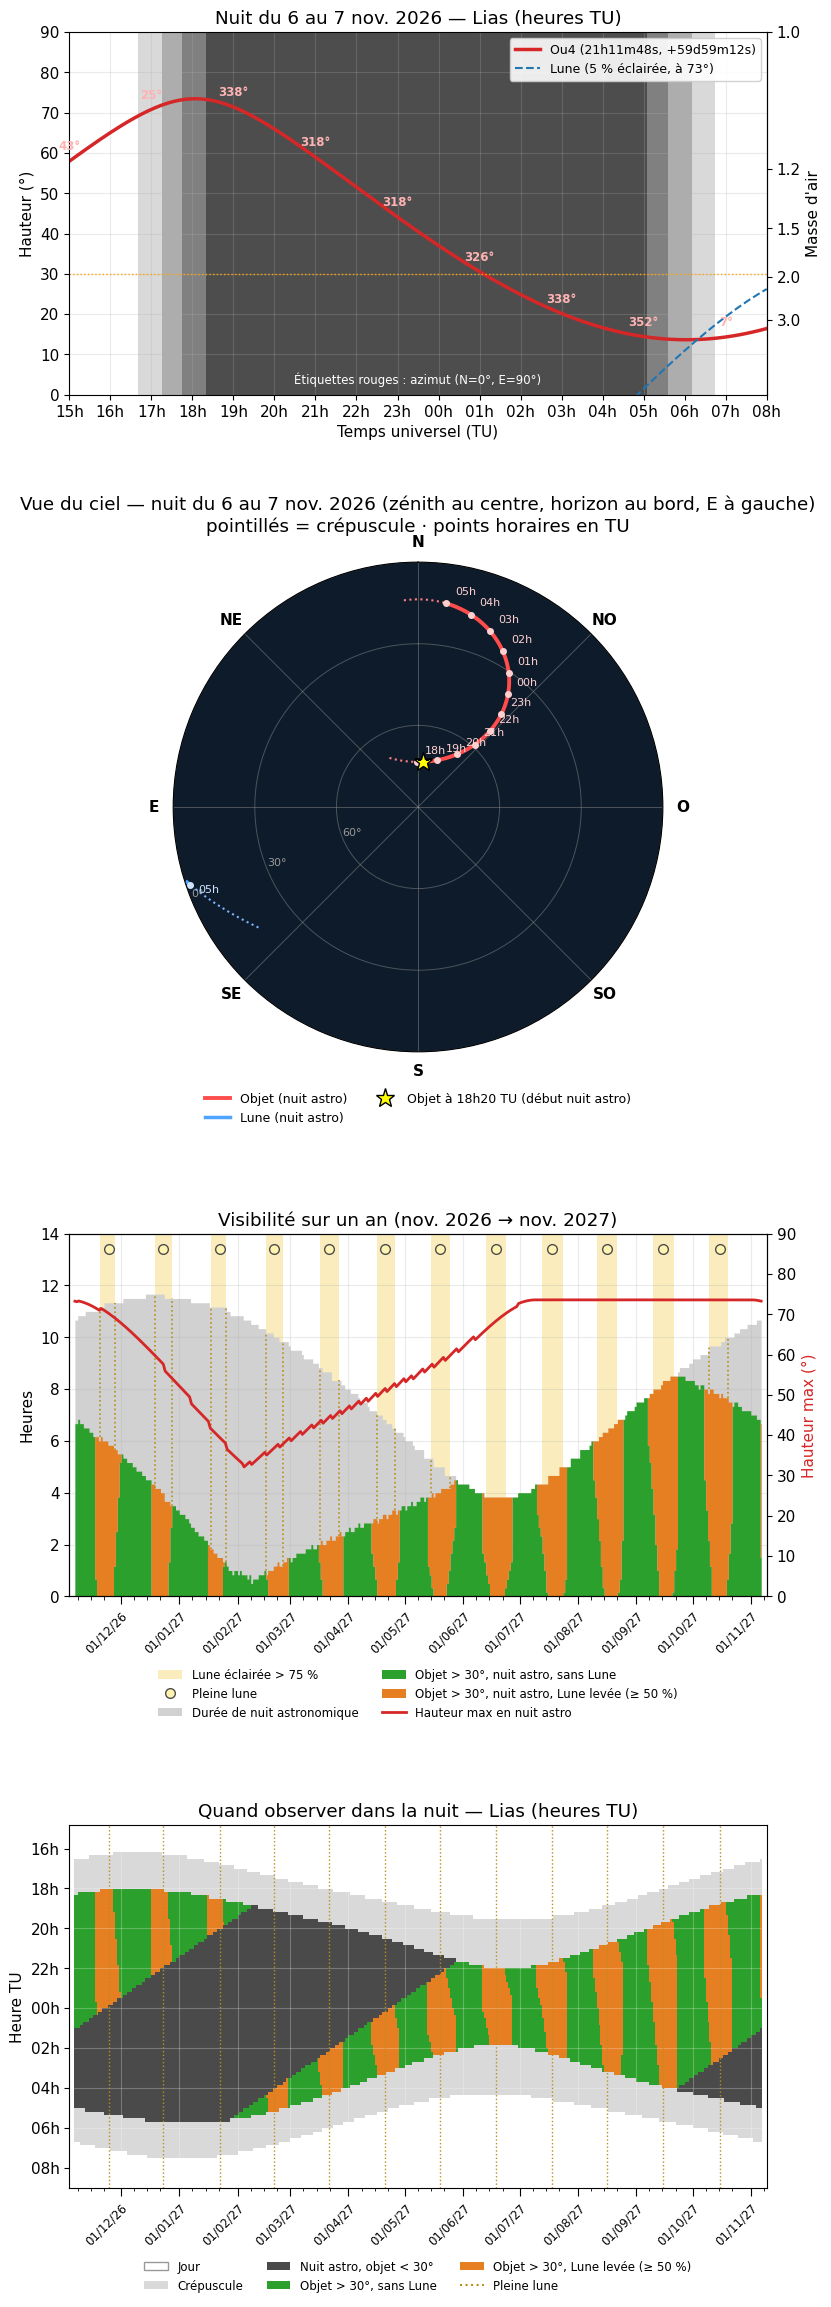

In [6]:
plt.rcParams.update({"font.size": 11})
fig = plt.figure(figsize=(9, 28))
gs = fig.add_gridspec(7, 1, height_ratios=[1, 0.38, 1.35, 0.42, 1, 0.55, 1], hspace=0.05)
ax1 = fig.add_subplot(gs[0])
axs = fig.add_subplot(gs[2], projection="polar")
ax2 = fig.add_subplot(gs[4])
ax4 = fig.add_subplot(gs[6], sharex=ax2)
titre_nuit = f"nuit du {d0.day} au {d1.day} {MOIS[d1.month-1]} {d1.year}"

# ================= 1. La nuit =================
lvl = np.digitize(sun_alt, [-18, -12, -6, 0])          # 0 = nuit astro … 4 = jour
cmap = ListedColormap(["0.30", "0.50", "0.68", "0.85", "white"])
ax1.pcolormesh(mdates.date2num(loc_dt), [0, 90], lvl[None, :-1], cmap=cmap,
               norm=BoundaryNorm(np.arange(-0.5, 5.5), 5), shading="flat", zorder=0)
ax1.plot(loc_dt, alt_t, color="#d62728", lw=2.5, label=f"{OBJ_NAME} ({RA}, {DEC})")
ax1.plot(loc_dt, moon_alt, color="#1f77b4", lw=1.5, ls="--",
         label=f"Lune ({illum*100:.0f} % éclairée, à {sep_tm:.0f}°)")
ax1.axhline(ALT_MIN, color="orange", lw=1, ls=":")
ax1.set_ylim(0, 90)
ax1.set_xlim(loc_dt[0], loc_dt[-1])
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Hh", tz=UTC))
ax1.xaxis.set_major_locator(mdates.HourLocator(interval=1, tz=UTC))
ax1.set_xlabel("Temps universel (TU)")
ax1.set_ylabel("Hauteur (°)")
ax1.set_title(f"{titre_nuit[0].upper() + titre_nuit[1:]} — {SITE_NAME} (heures TU)")
ax1.legend(loc="upper right", fontsize=9, framealpha=0.9)
ax1.grid(alpha=0.25)
sec = ax1.secondary_yaxis("right", functions=(
    lambda h: 1 / np.sin(np.radians(np.clip(h, 1, 90))),
    lambda X: np.degrees(np.arcsin(1 / np.clip(X, 1, 60)))))
sec.set_ticks([1.0, 1.2, 1.5, 2.0, 3.0])
sec.set_ylabel("Masse d'air")
k_h = int(60 / STEP_NIGHT) * 2
for i in range(0, n, k_h):
    if alt_t[i] > 5:
        ax1.annotate(f"{az_t[i]:.0f}°", (loc_dt[i], alt_t[i]), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=8.5, color="#ffb3b3", fontweight="bold")
ax1.text(0.5, 0.03, "Étiquettes rouges : azimut (N=0°, E=90°)",
         transform=ax1.transAxes, fontsize=8.5, ha="center", color="white")

# ================= 2. Vue du ciel =================
axs.set_theta_zero_location("N")
axs.set_theta_direction(1)                 # anti-horaire : E à gauche (vue « tête en l'air »)
axs.set_rlim(0, 90)
axs.set_rticks([30, 60, 90])
axs.set_yticklabels(["60°", "30°", "0°"], fontsize=8, color="0.6")
axs.set_rlabel_position(112)
axs.set_thetagrids([0, 45, 90, 135, 180, 225, 270, 315],
                   ["N", "NE", "E", "SE", "S", "SO", "O", "NO"], fontsize=11, fontweight="bold")
axs.set_facecolor("#0d1b2a")
axs.grid(color="0.55", alpha=0.5, lw=0.7)

def sky(alt, az, mask, **kw):
    a = np.where(mask & (alt > 0), alt, np.nan)
    axs.plot(np.radians(az), 90 - a, **kw)

sky(alt_t, az_t, twil, color="#ff7f7f", lw=1.5, ls=":")
sky(alt_t, az_t, night, color="#ff4d4d", lw=2.8, label="Objet (nuit astro)")
sky(moon_alt, moon_az, twil | night, color="#7fb3ff", lw=1.5, ls=":")
sky(moon_alt, moon_az, night, color="#4da3ff", lw=2.5, label="Lune (nuit astro)")
for i, d in enumerate(loc_dt):
    if d.minute == 0 and sun_alt[i] < -12:
        for alt, az, c, dy in [(alt_t, az_t, "#ffd0d0", 1), (moon_alt, moon_az, "#cfe3ff", -1)]:
            if alt[i] > 0:
                axs.plot(np.radians(az[i]), 90 - alt[i], "o", ms=4, color=c)
                axs.annotate(f"{d:%H}h", (np.radians(az[i]), 90 - alt[i]),
                             textcoords="offset points", xytext=(6, 6 * dy), fontsize=8, color=c)
i0 = np.argmax(night)
axs.plot(np.radians(az_t[i0]), 90 - alt_t[i0], "*", ms=14, color="yellow",
         markeredgecolor="k", label=f"Objet à {loc_dt[i0]:%Hh%M} TU (début nuit astro)")
axs.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=9, frameon=False)
axs.set_title(f"Vue du ciel — {titre_nuit} (zénith au centre, horizon au bord, E à gauche)\n"
              "pointillés = crépuscule · points horaires en TU", pad=22)

# ================= 3. Sur un an =================
# Bandes « pleine lune » : remplies seulement au-dessus des barres (derrière elles),
# prolongées en pointillés dans la seule zone grise (aucun tracé dans le vert/orange).
fm = res_illum > ILLUM_BANDE
edges = np.flatnonzero(np.diff(np.r_[0, fm.astype(int), 0]))
for k, (a_, b_) in enumerate(zip(edges[::2], edges[1::2])):
    xa, xb = days[a_] - timedelta(hours=12), days[b_ - 1] + timedelta(hours=12)
    ax2.axvspan(xa, xb, color="#f5d76e", alpha=0.45, lw=0, zorder=0,
                label=f"Lune éclairée > {ILLUM_BANDE*100:.0f} %" if k == 0 else None)
    for j, x in ((a_, xa), (b_ - 1, xb)):
        if res_dark[j] > res_hours[j] + 0.1:
            ax2.vlines(x, res_hours[j], res_dark[j], colors="#b8901a",
                       linestyles=":", lw=1.2, zorder=4)
ax2.plot([days[i] for i in pl], [13.4] * len(pl), "o", ms=7, mfc="#fff3b0", mec="0.3",
         label="Pleine lune", zorder=5)

# Aires continues (fill_between en escalier) plutôt que des barres d'un jour :
# pas d'interstices entre barres, donc rien ne transparaît dans le vert / orange.
ax2.fill_between(days, 0, res_dark, step="mid", color="0.82", lw=0,
                 label="Durée de nuit astronomique", zorder=1)
ax2.fill_between(days, 0, res_clean, step="mid", color="#2ca02c", lw=0,
                 label=f"Objet > {ALT_MIN}°, nuit astro, sans Lune", zorder=2)
ax2.fill_between(days, res_clean, res_hours, step="mid", color="#e67e22", lw=0,
                 label=f"Objet > {ALT_MIN}°, nuit astro, Lune levée (≥ {ILLUM_GENE*100:.0f} %)", zorder=2)
ax2.set_ylabel("Heures")
ax2.set_ylim(0, 14)
ax2.grid(alpha=0.25)
ax3 = ax2.twinx()
ax3.plot(days, res_max, color="#d62728", lw=2, label="Hauteur max en nuit astro")
ax3.set_ylim(0, 90)
ax3.set_ylabel("Hauteur max (°)", color="#d62728")
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=1))      # graduation au 1er du mois
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax2.xaxis.set_minor_locator(mdates.DayLocator(bymonthday=[8, 15, 22]))  # repères hebdo
ax2.tick_params(axis="x", which="major", labelsize=8.5, length=6)
ax2.tick_params(axis="x", which="minor", length=3)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax2.set_xlim(days[0] - timedelta(days=3), days[-1] + timedelta(days=3))
dN = days[-1]
ax2.set_title(f"Visibilité sur un an ({MOIS[d0.month-1]} {d0.year} → {MOIS[dN.month-1]} {dN.year})")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.17),
           fontsize=8.5, ncol=2, frameon=False)

# ================= 4. Carte date × heure TU =================
from matplotlib.patches import Patch
cols4 = ["white", "#d9d9d9", "#4a4a4a", "#2ca02c", "#e67e22"]
x_e = mdates.date2num(days[0]) - 0.5 + np.arange(len(days) + 1)
dy = STEP_YEAR / 60
y_e = np.r_[y_ut - dy / 2, y_ut[-1] + dy / 2]
ax4.pcolormesh(x_e, y_e, cat.T, cmap=ListedColormap(cols4),
               norm=BoundaryNorm(np.arange(-0.5, 5.5), 5), shading="flat", rasterized=True)
for i in pl:                                     # pleines lunes
    ax4.axvline(mdates.date2num(days[i]), color="#b8901a", ls=":", lw=1)
yt = np.arange(np.ceil(y_ut[0] / 2) * 2, y_ut[-1] + 0.01, 2)
ax4.set_yticks(yt)
ax4.set_yticklabels([f"{int(v % 24):02d}h" for v in yt])
ax4.set_ylim(y_ut[-1] + dy / 2, y_ut[0] - dy / 2)       # soir en haut, matin en bas
ax4.set_ylabel("Heure TU")
ax4.set_title(f"Quand observer dans la nuit — {SITE_NAME} (heures TU)")
ax4.grid(alpha=0.25, color="white")
ax4.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=1))
ax4.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax4.xaxis.set_minor_locator(mdates.DayLocator(bymonthday=[8, 15, 22]))
ax4.tick_params(axis="x", which="major", labelsize=8.5, length=6)
plt.setp(ax4.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax2.tick_params(axis="x", labelbottom=True)
ax4.legend(handles=[Patch(fc=cols4[0], ec="0.6", label="Jour"),
                    Patch(fc=cols4[1], label="Crépuscule"),
                    Patch(fc=cols4[2], label=f"Nuit astro, objet < {ALT_MIN}°"),
                    Patch(fc=cols4[3], label=f"Objet > {ALT_MIN}°, sans Lune"),
                    Patch(fc=cols4[4], label=f"Objet > {ALT_MIN}°, Lune levée (≥ {ILLUM_GENE*100:.0f} %)"),
                    plt.Line2D([], [], color="#b8901a", ls=":", label="Pleine lune")],
           loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=8.5, ncol=3, frameon=False)

fig.savefig(OUTFILE, dpi=150, bbox_inches="tight")
plt.show()

## Télécharger l'image (Colab)

In [7]:
try:
    from google.colab import files
    files.download(OUTFILE)
except ImportError:
    print(f"Image enregistrée : {OUTFILE}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>